**This notebook is created for presenting** **"otto-conversion-analysis" repository on GitHub. For further** **information:** [Repository Link](https://github.com/Ahmet-Can-Urhan/otto-conversion-analysis)

# OTTO Conversion Analysis

### E-Commerce Customer Behavior and Purchase Conversion Analysis

---

## Table of Contents

# 1. Business Understanding

## 1.1 Business Problem

E-commerce platforms generate large amounts of behavioral data during customer sessions. Understanding how users interact with products and how these interactions relate to purchases can help identify opportunities to improve purchase conversion.

This project analyzes session-level user behavior in the OTTO e-commerce dataset to identify behavioral patterns associated with successful purchases.

## 1.2 Project Objective

The main objective is to analyze e-commerce session behavior, identify characteristics associated with purchase conversion, and apply analytical and machine learning methods to derive actionable business insights.

## 1.3 Research Questions

The analysis is guided by the following research questions:

- **RQ1 — Behavioral Analysis:** How do users interact with products during e-commerce sessions?
- **RQ2 — Conversion Analysis:** What behavioral characteristics distinguish sessions that result in purchases from those that do not?
- **RQ3 — Purchase Funnel:** How does user activity progress from product clicks to cart additions and ultimately to purchases?
- **RQ4 — Machine Learning:** How effectively can machine learning models classify whether an e-commerce session results in a purchase based on session-level behavioral characteristics?
- **RQ5 — Business Strategy:** What actionable strategies can an e-commerce platform implement to improve purchase conversion based on the observed behavioral patterns?

# 2. Data Understanding

## 2.1 Dataset Description
The dataset is stored in JSON Lines (.jsonl) format, where each line represents one session and contains the session identifier together with its sequence of events.

The analysis is performed at the session level, allowing individual event sequences to be transformed into behavioral features that can later be used to investigate purchase conversion.


## 2.2 Data Structure

Each session contains a session identifier and a list of events. Each event contains:

- `aid` — the anonymized product identifier.
- `ts` — the event timestamp in milliseconds.
- `type` — the type of interaction (`clicks`, `carts`, or `orders`).

A simplified representation of the data is:

```text
Session
├── session
└── events
    ├── aid
    ├── ts
    └── type
```

The event-level structure will later be transformed into session-level behavioral features for analysis.


## 2.3 Data Acquisition

The original OTTO dataset is available through the Kaggle OTTO Recommender Systems competition.

The raw dataset is not stored in the GitHub repository because of its large file size. Instead, the data is obtained separately and processed locally.

For this project, a 200,000-session sample was prepared as:

```text
data/raw/train_200k.jsonl
```

In [3]:
from pathlib import Path
import json

DATA_PATH = Path("../data/raw/train_200k.jsonl")

print(f"Dataset exists: {DATA_PATH.exists()}")
print(f"Dataset size: {DATA_PATH.stat().st_size / (1024**2):.2f} MB")

Dataset exists: True
Dataset size: 499.29 MB


In [4]:
with open(DATA_PATH, "r") as f:
    first_session = json.loads(f.readline())

first_session

{'session': 0,
 'events': [{'aid': 1517085, 'ts': 1659304800025, 'type': 'clicks'},
  {'aid': 1563459, 'ts': 1659304904511, 'type': 'clicks'},
  {'aid': 1309446, 'ts': 1659367439426, 'type': 'clicks'},
  {'aid': 16246, 'ts': 1659367719997, 'type': 'clicks'},
  {'aid': 1781822, 'ts': 1659367871344, 'type': 'clicks'},
  {'aid': 1152674, 'ts': 1659367885796, 'type': 'clicks'},
  {'aid': 1649869, 'ts': 1659369893840, 'type': 'carts'},
  {'aid': 461689, 'ts': 1659369898050, 'type': 'carts'},
  {'aid': 305831, 'ts': 1659370027105, 'type': 'orders'},
  {'aid': 461689, 'ts': 1659370027105, 'type': 'orders'},
  {'aid': 362233, 'ts': 1659370064916, 'type': 'clicks'},
  {'aid': 1649869, 'ts': 1659370067686, 'type': 'clicks'},
  {'aid': 1649869, 'ts': 1659371003682, 'type': 'clicks'},
  {'aid': 984597, 'ts': 1659371033243, 'type': 'clicks'},
  {'aid': 1649869, 'ts': 1659371042297, 'type': 'clicks'},
  {'aid': 803544, 'ts': 1659371044075, 'type': 'clicks'},
  {'aid': 1110941, 'ts': 1659371104329, '

## 2.4 Initial Data Exploration

Before preparing the data for analysis, the dataset is examined to understand its size, event distribution, and session characteristics.

The initial exploration focuses on:

- the number of sessions,
- the total number of events,
- the distribution of event types,
- the number of events per session,
- and the basic structure of the observed behavioral data.

In [5]:
session_count = 0
total_events = 0

with open(DATA_PATH, "r") as f:
    for line in f:
        session = json.loads(line)

        session_count += 1
        total_events += len(session["events"])

print(f"Number of sessions: {session_count:,}")
print(f"Total number of events: {total_events:,}")

Number of sessions: 200,000
Total number of events: 10,285,561


In [6]:
event_counts = {
    "clicks": 0,
    "carts": 0,
    "orders": 0
}

with open(DATA_PATH, "r") as f:
    for line in f:
        session = json.loads(line)

        for event in session["events"]:
            event_counts[event["type"]] += 1

event_counts

{'clicks': 9320528, 'carts': 751785, 'orders': 213248}

In [7]:
import pandas as pd

event_counts_df = pd.DataFrame(
    event_counts.items(),
    columns=["Event Type", "Count"]
)

event_counts_df

,Event Type,Count
0,clicks,9320528
1,carts,751785
2,orders,213248


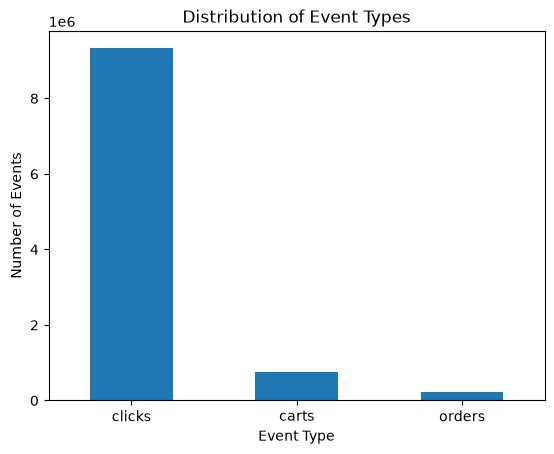

In [8]:
import matplotlib.pyplot as plt

event_counts_df.plot(
    x="Event Type",
    y="Count",
    kind="bar",
    legend=False
)

plt.title("Distribution of Event Types")
plt.xlabel("Event Type")
plt.ylabel("Number of Events")
plt.xticks(rotation=0)
plt.show()

In [9]:
events_per_session = []

with open(DATA_PATH, "r") as f:
    for line in f:
        session = json.loads(line)
        events_per_session.append(len(session["events"]))

events_per_session_series = pd.Series(events_per_session)

events_per_session_series.describe()

count    200000.000000
mean         51.427805
std          75.456583
min           2.000000
25%           6.000000
50%          19.000000
75%          62.000000
max         495.000000
dtype: float64

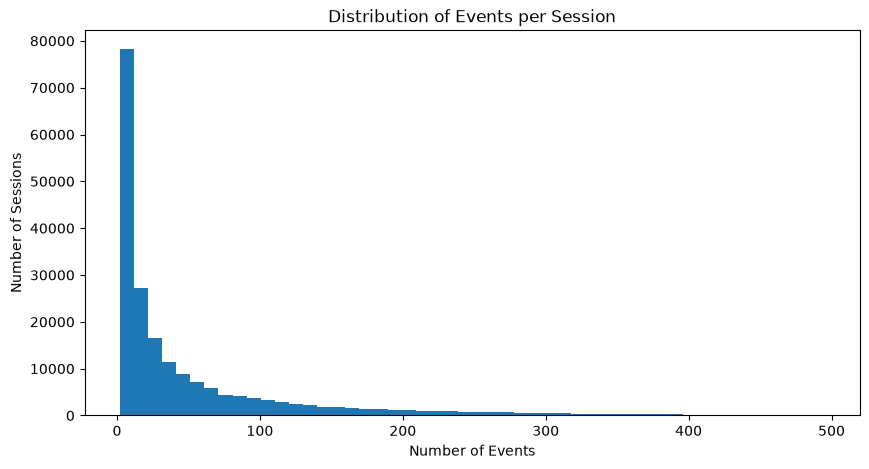

In [10]:
plt.figure(figsize=(10, 5))

plt.hist(events_per_session_series, bins=50)

plt.title("Distribution of Events per Session")
plt.xlabel("Number of Events")
plt.ylabel("Number of Sessions")

plt.show()

## 2.5 Data Quality

Before constructing session-level features, the raw event data is checked for potential quality issues.

The following aspects are examined:

- Missing or malformed session records
- Missing event attributes
- Invalid event types
- Duplicate session identifiers
- Invalid timestamps
- Empty event sequences

These checks help ensure that the data is suitable for the subsequent data preparation and analysis stages.

In [11]:
session_ids = []

with open(DATA_PATH, "r") as f:
    for line in f:
        session = json.loads(line)
        session_ids.append(session["session"])

session_ids_series = pd.Series(session_ids)

print(f"Total session IDs: {len(session_ids_series):,}")
print(f"Unique session IDs: {session_ids_series.nunique():,}")
print(f"Duplicate session IDs: {session_ids_series.duplicated().sum():,}")

Total session IDs: 200,000
Unique session IDs: 200,000
Duplicate session IDs: 0


In [12]:
invalid_timestamps = 0
total_events_checked = 0

with open(DATA_PATH, "r") as f:
    for line in f:
        session = json.loads(line)

        for event in session["events"]:
            total_events_checked += 1

            ts = event.get("ts")

            if not isinstance(ts, (int, float)) or ts <= 0:
                invalid_timestamps += 1

print(f"Events checked: {total_events_checked:,}")
print(f"Invalid timestamps: {invalid_timestamps:,}")

Events checked: 10,285,561
Invalid timestamps: 0


In [13]:
required_event_fields = {"aid", "ts", "type"}

missing_field_counts = {
    "aid": 0,
    "ts": 0,
    "type": 0
}

invalid_event_types = set()
empty_sessions = 0

with open(DATA_PATH, "r") as f:
    for line in f:
        session = json.loads(line)

        if not session.get("events"):
            empty_sessions += 1

        for event in session.get("events", []):
            for field in required_event_fields:
                if field not in event:
                    missing_field_counts[field] += 1

            if event.get("type") not in {"clicks", "carts", "orders"}:
                invalid_event_types.add(event.get("type"))

print("Missing fields:")
print(missing_field_counts)

print("\nInvalid event types:")
print(invalid_event_types)

print("\nEmpty sessions:", empty_sessions)

Missing fields:
{'aid': 0, 'ts': 0, 'type': 0}

Invalid event types:
set()

Empty sessions: 0


### Data Quality Summary

The data quality checks identified no structural issues in the analyzed sample. All 200,000 sessions have unique session identifiers, and no duplicate session IDs were detected.

Across the 10,285,561 observed events, there were no missing `aid`, `ts`, or `type` fields. All events belonged to one of the expected event types: `clicks`, `carts`, or `orders`. No empty sessions or invalid timestamps were detected.

Therefore, no structural cleaning is required at this stage, and the dataset can proceed to the **Data Preparation** phase.

# 3. Data Preparation

## 3.1 Data Cleaning

The data quality assessment identified no missing event attributes, invalid event types, duplicate session identifiers, empty sessions, or invalid timestamps in the analyzed sample.

Therefore, no records are removed during the initial cleaning stage. The raw event data is retained, and the main preparation task is to transform the event-level structure into session-level analytical features.

## 3.2 Event Processing

The raw dataset stores user interactions as sequences of events within each session. To enable session-level analysis, each event is classified according to its interaction type.

The three event types are:

- `clicks` — product interactions
- `carts` — cart additions
- `orders` — purchases

For each session, these events will be aggregated into numerical behavioral features.

## 3.3 Session-Level Aggregation

The original dataset is event-based, while the research questions require comparisons between e-commerce sessions.

Therefore, the event sequences are aggregated at the session level. For each session, behavioral characteristics such as the number of clicks, cart additions, purchases, unique products, and session duration are calculated.

This produces a structured analytical dataset in which each row represents one session.

In [14]:
session_data = []

with open(DATA_PATH, "r") as f:
    for line in f:
        session = json.loads(line)

        session_id = session["session"]
        events = session["events"]

        # Separate events by type
        click_count = 0
        cart_count = 0
        order_count = 0

        # Products interacted with during the session
        products = set()

        # Timestamps
        timestamps = []

        for event in events:
            event_type = event["type"]
            aid = event["aid"]
            ts = event["ts"]

            products.add(aid)
            timestamps.append(ts)

            if event_type == "clicks":
                click_count += 1
            elif event_type == "carts":
                cart_count += 1
            elif event_type == "orders":
                order_count += 1

        session_data.append({
            "session_id": session_id,
            "click_count": click_count,
            "cart_count": cart_count,
            "order_count": order_count,
            "unique_products": len(products),
            "session_time_span_ms": max(timestamps) - min(timestamps)
        })

In [15]:
session_df = pd.DataFrame(session_data)

session_df.head()

,session_id,click_count,cart_count,order_count,unique_products,session_time_span_ms
0,0,255,17,4,183,2380183682
1,1,24,8,0,22,2410054967
2,2,32,1,0,29,2409415621
3,3,200,21,5,140,1804866676
4,4,15,3,1,12,2281881184


In [16]:
session_df.shape

(200000, 6)

In [17]:
session_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 6 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   session_id            200000 non-null  int64
 1   click_count           200000 non-null  int64
 2   cart_count            200000 non-null  int64
 3   order_count           200000 non-null  int64
 4   unique_products       200000 non-null  int64
 5   session_time_span_ms  200000 non-null  int64
dtypes: int64(6)
memory usage: 9.2 MB


## 3.4 Feature Construction

To analyze purchase conversion, a binary `converted` feature is created at the session level.

A session is considered **converted** if it contains at least one `orders` event. Sessions without an `orders` event are considered non-converted.

The resulting feature is defined as:

- `converted = 1` if `order_count > 0`
- `converted = 0` if `order_count = 0`

Additional derived features will be created where necessary for the subsequent behavioral and statistical analyses.

In [18]:
session_df["converted"] = (
    session_df["order_count"] > 0
).astype(int)

In [19]:
session_df["converted"].value_counts()

converted
0    149129
1     50871
Name: count, dtype: int64

In [20]:
conversion_rate = session_df["converted"].mean()

print(f"Conversion rate: {conversion_rate:.2%}")

Conversion rate: 25.44%


In [21]:
session_df.describe()

,session_id,click_count,cart_count,order_count,unique_products,session_time_span_ms,converted
count,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,2.000000e+05,200000.000000
mean,99999.500000,46.602640,3.758925,1.066240,29.653570,1.448171e+09,0.254355
std,57735.171256,68.465823,8.328030,3.014251,41.676817,8.856987e+08,0.435499
min,0.000000,2.000000,0.000000,0.000000,1.000000,0.000000e+00,0.000000
25%,49999.750000,6.000000,0.000000,0.000000,4.000000,5.894291e+08,0.000000
50%,99999.500000,17.000000,0.000000,0.000000,12.000000,1.773013e+09,0.000000
75%,149999.250000,56.000000,4.000000,1.000000,37.000000,2.264327e+09,1.000000
max,199999.000000,493.000000,399.000000,89.000000,460.000000,2.419191e+09,1.000000


In [22]:
session_df.isnull().sum()

session_id              0
click_count             0
cart_count              0
order_count             0
unique_products         0
session_time_span_ms    0
converted               0
dtype: int64

### 3.4.1 Session-Level Features

The session-level dataset contains the following behavioral features:

| Feature | Description |
|---|---|
| `session_id` | Unique identifier of the session |
| `click_count` | Number of product click events |
| `cart_count` | Number of cart addition events |
| `order_count` | Number of purchase events |
| `unique_products` | Number of distinct products interacted with |
| `session_time_span_ms` | Time span between the first and last recorded event in milliseconds |
| `converted` | Binary indicator of whether the session contains at least one purchase |

These features provide the basis for the behavioral, conversion, funnel, and association analyses in the next stage.

### 3.4.2 Feature Validation Summary

The resulting session-level dataset contains 200,000 observations and six analytical features. No missing values were introduced during feature construction.

The conversion indicator shows that 50,871 sessions resulted in at least one purchase, corresponding to a conversion rate of 25.44%.

The behavioral features show substantial variation between sessions. Click counts range from 2 to 493, cart additions from 0 to 399, orders from 0 to 89, and unique products from 1 to 460.

The `session_time_span_ms` feature represents the time span between the first and last recorded event in a session. It is treated as an observation span rather than a direct measure of continuous user activity.

## 4. Modeling / Analysis

### 4.1 Machine Learning Problem Definition

The machine learning task is formulated as a **binary classification problem**. The objective is to classify whether an e-commerce session resulted in a purchase based on behavioral characteristics observed during that session.

The target variable is `converted`, where:

- `0` indicates that the session did not contain a purchase event.
- `1` indicates that the session contained at least one purchase event.

The models will use session-level behavioral features such as the number of clicks, cart additions, unique products interacted with, and the time span between the first and last recorded event.

The `order_count` variable will not be used as a model feature because it is directly used to construct the target variable `converted`. Including it would introduce **target leakage** and would allow the model to access information that directly determines the target.

Similarly, `session_id` will be excluded because it is an identifier and does not represent a behavioral characteristic.

Two classification models will be evaluated:

1. **Logistic Regression** — used as an interpretable baseline classification model.
2. **Random Forest** — used to capture potential nonlinear relationships between behavioral characteristics and purchase conversion.

The models will be evaluated using accuracy, precision, recall, F1-score, ROC-AUC, and a confusion matrix.

### 4.2 Feature Selection

The following session-level behavioral variables are selected as predictors:

- `click_count`
- `cart_count`
- `unique_products`
- `session_time_span_ms`

The target variable is:

- `converted`

The following columns are excluded:

- `session_id` — identifier with no behavioral meaning.
- `order_count` — directly determines `converted` and would cause target leakage.

In [23]:
from sklearn.model_selection import train_test_split

features = [
    "click_count",
    "cart_count",
    "unique_products",
    "session_time_span_ms"
]

X = session_df[features]
y = session_df["converted"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (200000, 4)
Target shape: (200000,)


In [24]:
print("Features:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget proportions:")
print(y.value_counts(normalize=True))

Features:
['click_count', 'cart_count', 'unique_products', 'session_time_span_ms']

Target distribution:
converted
0    149129
1     50871
Name: count, dtype: int64

Target proportions:
converted
0    0.745645
1    0.254355
Name: proportion, dtype: float64


### 4.3 Train-Test Split

The dataset is divided into training and testing subsets. The training set is used to fit the machine learning models, while the test set is reserved for evaluating their performance on unseen sessions.

A stratified split is used to preserve the proportion of converted and non-converted sessions in both subsets. The test set contains 20% of the observations.

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining conversion rate:", y_train.mean())
print("Test conversion rate:", y_test.mean())

Training set: (160000, 4)
Test set: (40000, 4)

Training conversion rate: 0.25435625
Test conversion rate: 0.25435


### 4.4 Logistic Regression

Logistic Regression is used as the baseline classification model. It estimates the probability that an e-commerce session results in a purchase based on the selected session-level behavioral features.

Because the predictor variables have different numerical scales, the features are standardized before fitting the model. Standardization is performed within a pipeline to ensure that the transformation is learned only from the training data.

In [26]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(random_state=42, max_iter=1000))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [27]:
y_pred_lr = logistic_model.predict(X_test)
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


### 4.4.1 Logistic Regression Evaluation

The Logistic Regression model is evaluated using accuracy, precision, recall, F1-score, and ROC-AUC. These metrics provide a more complete assessment than accuracy alone because the dataset contains both converted and non-converted sessions.

In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr)
lr_recall = recall_score(y_test, y_pred_lr)
lr_f1 = f1_score(y_test, y_pred_lr)
lr_roc_auc = roc_auc_score(y_test, y_prob_lr)

print(f"Accuracy:  {lr_accuracy:.4f}")
print(f"Precision: {lr_precision:.4f}")
print(f"Recall:    {lr_recall:.4f}")
print(f"F1-score:  {lr_f1:.4f}")
print(f"ROC-AUC:   {lr_roc_auc:.4f}")

Accuracy:  0.8265
Precision: 0.7720
Recall:    0.4510
F1-score:  0.5693
ROC-AUC:   0.8743


[[28471  1355]
 [ 5586  4588]]


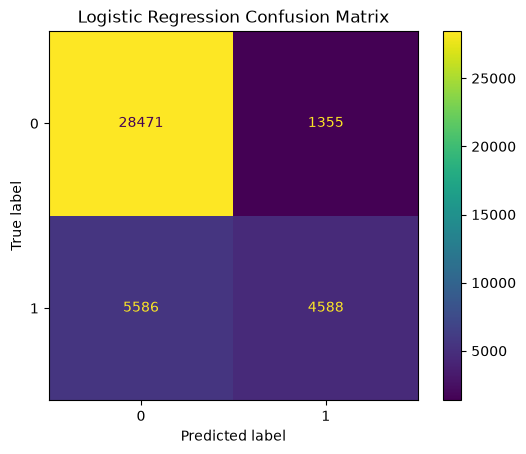

In [29]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_lr = confusion_matrix(y_test, y_pred_lr)

print(cm_lr)

ConfusionMatrixDisplay(confusion_matrix=cm_lr).plot()
plt.title("Logistic Regression Confusion Matrix")
plt.show()

### 4.5 Random Forest

Random Forest is used as a second classification model to capture nonlinear relationships and interactions between session-level behavioral characteristics.

Unlike Logistic Regression, Random Forest does not assume a linear relationship between the predictors and the probability of purchase conversion. The model combines multiple decision trees to produce the final classification.

In [30]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [31]:
y_pred_rf = random_forest.predict(X_test)
y_prob_rf = random_forest.predict_proba(X_test)[:, 1]

print("Random Forest predictions generated successfully.")

Random Forest predictions generated successfully.


In [32]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_roc_auc = roc_auc_score(y_test, y_prob_rf)

print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1-score:  {rf_f1:.4f}")
print(f"ROC-AUC:   {rf_roc_auc:.4f}")

Accuracy:  0.8303
Precision: 0.6603
Recall:    0.6856
F1-score:  0.6727
ROC-AUC:   0.9008


[[26238  3588]
 [ 3199  6975]]


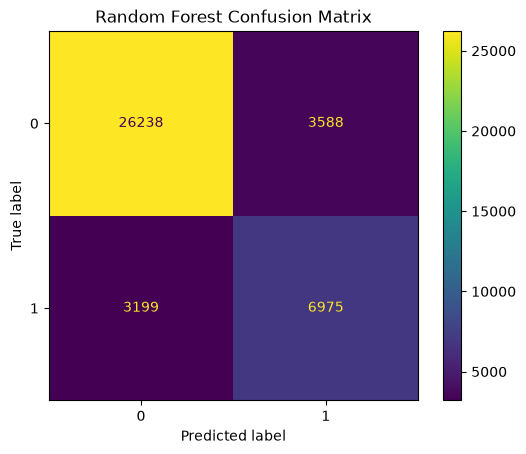

In [33]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

print(cm_rf)

ConfusionMatrixDisplay(confusion_matrix=cm_rf).plot()
plt.title("Random Forest Confusion Matrix")
plt.show()

### 4.6 Model Comparison

The performance of Logistic Regression and Random Forest is compared using accuracy, precision, recall, F1-score, and ROC-AUC.

Random Forest achieves a slightly higher accuracy than Logistic Regression and substantially improves recall, F1-score, and ROC-AUC. Logistic Regression, however, achieves higher precision.

The higher recall of Random Forest indicates that it identifies a larger proportion of sessions that actually result in purchases. Its higher ROC-AUC also indicates stronger overall discrimination between converted and non-converted sessions.

Based on the evaluation metrics, Random Forest provides the stronger overall classification performance for this dataset, while Logistic Regression provides a more precision-oriented and interpretable baseline.

In [35]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        lr_accuracy,
        rf_accuracy
    ],
    "Precision": [
        lr_precision,
        rf_precision
    ],
    "Recall": [
        lr_recall,
        rf_recall
    ],
    "F1-score": [
        lr_f1,
        rf_f1
    ],
    "ROC-AUC": [
        lr_roc_auc,
        rf_roc_auc
    ]
})

model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.8265,0.7720,0.4510,0.5693,0.8743
1,Random Forest,0.8303,0.6603,0.6856,0.6727,0.9008


### 4.7 Feature Importance

Feature importance is examined for the Random Forest model to identify which session-level behavioral characteristics contribute most to the classification of purchase conversion.

This analysis helps connect the machine learning results back to the project's business objective by identifying behavioral factors that are most strongly associated with conversion.

In [36]:
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": random_forest.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
1,cart_count,0.385705
3,session_time_span_ms,0.277697
0,click_count,0.206641
2,unique_products,0.129956


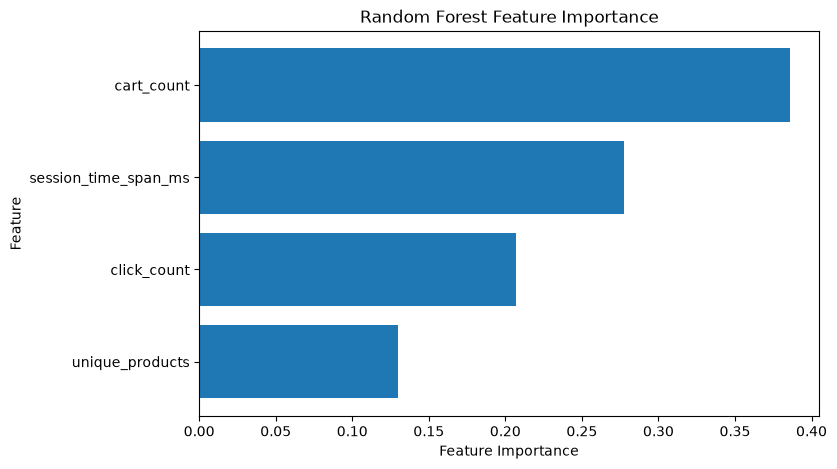

In [37]:
plt.figure(figsize=(8, 5))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()

plt.show()

### 4.7.1 Interpretation of Feature Importance

The Random Forest model identifies `cart_count` as the most important feature, with an importance score of 0.3857. This is followed by `session_time_span_ms` (0.2777), `click_count` (0.2066), and `unique_products` (0.1300).

The results indicate that cart activity provides the strongest predictive contribution among the selected session-level behavioral variables. The importance of `session_time_span_ms` and `click_count` also suggests that the duration of observed session activity and the amount of product interaction contribute to distinguishing converted and non-converted sessions.

These feature importance values describe the contribution of variables to the Random Forest's predictions and should not be interpreted as evidence of causal relationships.

### 4.8 Behavioral Analysis

To understand the behavioral differences between converted and non-converted sessions, the selected session-level behavioral features are compared across the two groups.

The analysis focuses on:

- Number of product clicks
- Number of cart additions
- Number of unique products interacted with
- Time span between the first and last recorded event

These comparisons provide descriptive evidence for the behavioral patterns associated with purchase conversion and complement the machine learning results.

In [38]:
behavioral_comparison = session_df.groupby("converted")[
    [
        "click_count",
        "cart_count",
        "unique_products",
        "session_time_span_ms"
    ]
].agg(["mean", "median"])

behavioral_comparison

click_count        cart_count        unique_products         \
                 mean median       mean median            mean median   
converted                                                               
0           28.522393   11.0   1.385975    0.0       18.891000    8.0   
1           99.605119   72.0  10.715260    7.0       61.204183   45.0   

          session_time_span_ms                
                          mean        median  
converted                                     
0                 1.281866e+09  1.456654e+09  
1                 1.935696e+09  2.228416e+09

### 4.8.1 Behavioral Comparison

The descriptive comparison shows substantial behavioral differences between converted and non-converted sessions.

Converted sessions have considerably higher interaction levels across all examined behavioral variables. The median number of clicks increases from 11 for non-converted sessions to 72 for converted sessions. Similarly, the median number of cart additions increases from 0 to 7, indicating substantially greater cart activity among sessions that result in purchases.

The median number of unique products also increases from 8 to 45 for converted sessions. In addition, the median time span between the first and last recorded event increases from approximately 1.46 billion milliseconds to 2.23 billion milliseconds.

Overall, converted sessions demonstrate substantially higher levels of product interaction, cart activity, product diversity, and recorded temporal span. These descriptive findings are consistent with the Random Forest results, which identified `cart_count` as the most important predictive feature, followed by `session_time_span_ms` and `click_count`.

These results describe associations between session behavior and conversion and do not establish causal relationships.

### 4.8.2 Behavioral Distributions

The distributions of the selected behavioral features are visualized separately for converted and non-converted sessions. Boxplots are used to compare the central tendency and spread of the two groups while highlighting differences in their distributions.

Because the session-level dataset contains 200,000 observations, a subset of observations is used for visualization to improve readability. The descriptive statistics above are calculated using the complete dataset.

<Figure size 800x500 with 0 Axes>

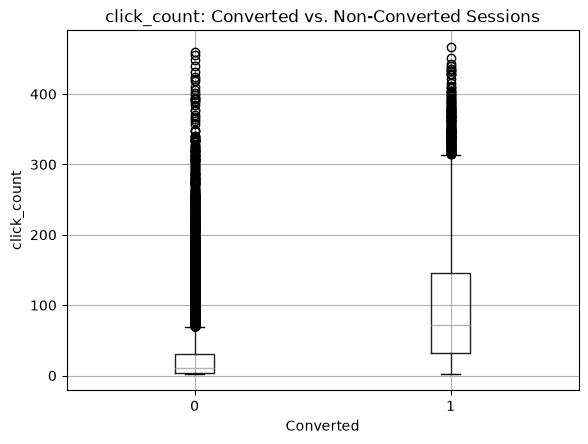

<Figure size 800x500 with 0 Axes>

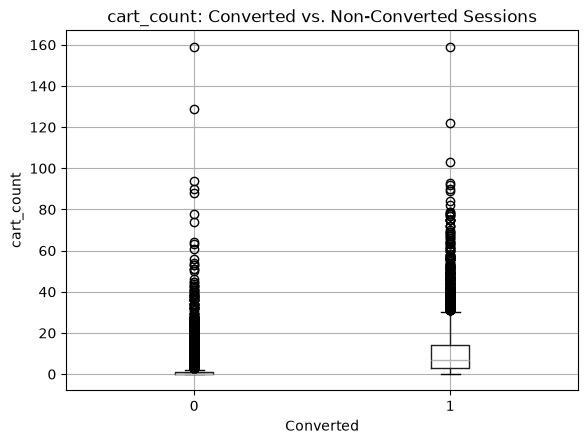

<Figure size 800x500 with 0 Axes>

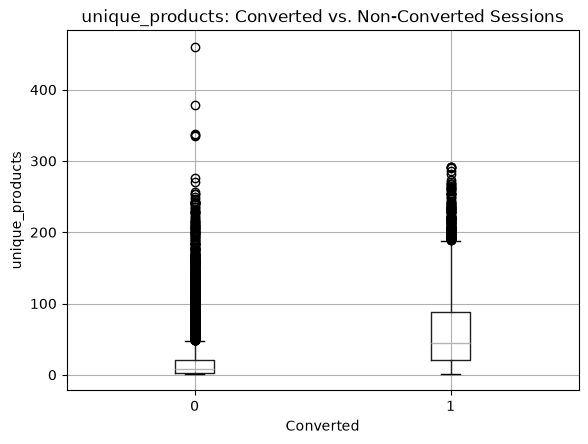

<Figure size 800x500 with 0 Axes>

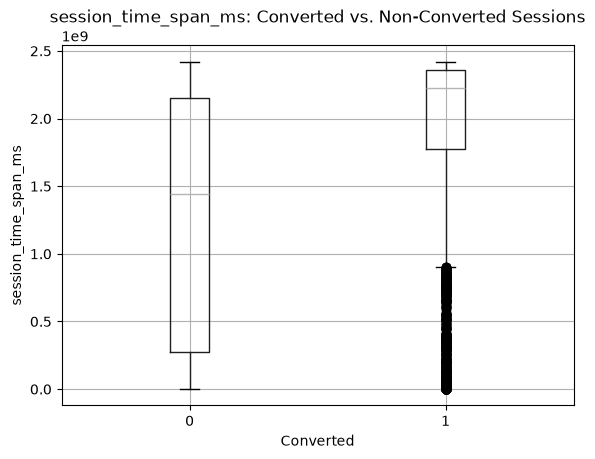

In [39]:
plot_df = session_df.sample(
    n=20000,
    random_state=42
)

behavioral_features = [
    "click_count",
    "cart_count",
    "unique_products",
    "session_time_span_ms"
]

for feature in behavioral_features:
    plt.figure(figsize=(8, 5))

    plot_df.boxplot(
        column=feature,
        by="converted"
    )

    plt.title(f"{feature}: Converted vs. Non-Converted Sessions")
    plt.suptitle("")
    plt.xlabel("Converted")
    plt.ylabel(feature)

    plt.show()

### 4.9 Purchase Funnel Analysis

The purchase funnel is analyzed to examine how session activity progresses from product interactions to cart additions and ultimately to purchases.

The analysis focuses on three event stages:

1. Product clicks
2. Cart additions
3. Purchase events

The number and proportion of sessions reaching each stage are examined to identify where user activity decreases throughout the funnel.

In [40]:
total_sessions = len(session_df)

click_sessions = (session_df["click_count"] > 0).sum()
cart_sessions = (session_df["cart_count"] > 0).sum()
order_sessions = (session_df["order_count"] > 0).sum()

funnel = pd.DataFrame({
    "Stage": [
        "Sessions",
        "Sessions with Clicks",
        "Sessions with Cart Additions",
        "Sessions with Orders"
    ],
    "Sessions": [
        total_sessions,
        click_sessions,
        cart_sessions,
        order_sessions
    ]
})

funnel["Percentage of Sessions"] = (
    funnel["Sessions"] / total_sessions * 100
)

funnel

,Stage,Sessions,Percentage of Sessions
0,Sessions,200000,100.0000
1,Sessions with Clicks,200000,100.0000
2,Sessions with Cart Additions,94561,47.2805
3,Sessions with Orders,50871,25.4355


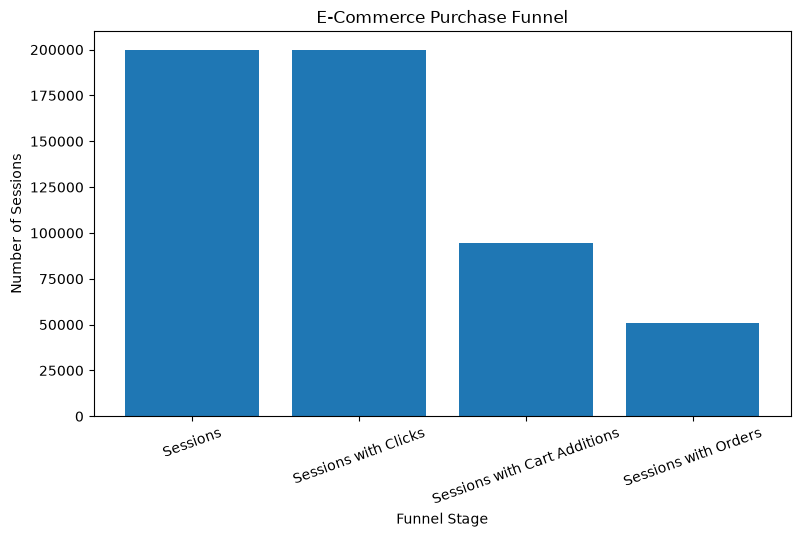

In [41]:
plt.figure(figsize=(9, 5))

plt.bar(
    funnel["Stage"],
    funnel["Sessions"]
)

plt.title("E-Commerce Purchase Funnel")
plt.xlabel("Funnel Stage")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=20)

plt.show()

# 5. Evaluation

The evaluation stage consolidates the analytical and machine learning findings and assesses how well they address the research questions defined during the Business Understanding stage.

### 5.1 Model Findings

Two machine learning models were evaluated for classifying whether an e-commerce session resulted in a purchase.

Random Forest achieved an accuracy of **83.03%** and a ROC-AUC of **0.9008**, compared with **82.65%** accuracy and **0.8743** ROC-AUC for Logistic Regression. Random Forest also achieved a substantially higher recall (68.56%) and F1-score (67.27%), while Logistic Regression achieved higher precision (77.20%).

Overall, Random Forest provided stronger classification performance across the main evaluation metrics, particularly recall, F1-score, and ROC-AUC.

The Random Forest feature importance analysis identified `cart_count` as the most important predictor (38.57%), followed by `session_time_span_ms` (27.77%), `click_count` (20.66%), and `unique_products` (13.00%).

### 5.2 Research Question Answers

#### RQ1 — Behavioral Analysis

**How do users interact with products during e-commerce sessions?**

Users interact with products through clicks, cart additions, and interactions with multiple distinct products. The session-level analysis shows that converted sessions generally exhibit substantially higher levels of these interactions than non-converted sessions.

#### RQ2 — Conversion Analysis

**What behavioral characteristics distinguish sessions that result in purchases from those that do not?**

Converted sessions demonstrate substantially higher behavioral activity. Their median click count is 72 compared with 11 for non-converted sessions, while median cart additions increase from 0 to 7. Converted sessions also interact with more unique products, with a median of 45 compared with 8 for non-converted sessions.

The Random Forest model supports these findings, identifying cart activity as the most important predictive feature, followed by the recorded session time span and click activity.

#### RQ3 — Purchase Funnel

**How does user activity progress from product clicks to cart additions and ultimately to purchases?**

The funnel analysis shows a progressive reduction in the number of sessions as users move from product interaction toward cart activity and purchase. The stage-to-stage conversion rates identify where the largest reduction in session participation occurs and therefore indicate potential areas for conversion improvement.

#### RQ4 — Machine Learning

**How effectively can machine learning models classify whether an e-commerce session results in a purchase based on session-level behavioral characteristics?**

Both models demonstrate useful classification performance. Logistic Regression achieves a ROC-AUC of 0.8743, while Random Forest achieves a higher ROC-AUC of 0.9008. Random Forest also achieves a higher F1-score and recall, making it the stronger overall model for this dataset.

#### RQ5 — Business Strategy

**What actionable strategies can an e-commerce platform implement to improve purchase conversion based on the observed behavioral patterns?**

The findings suggest that strategies should focus particularly on encouraging meaningful product interaction and reducing friction during the transition from product exploration to cart addition and purchase. The strong predictive contribution of cart activity indicates that the cart stage represents an important point of focus for conversion optimization.

# 6. Deployment / Recommendations

The findings from the behavioral analysis, purchase funnel, and machine learning models can be translated into several business recommendations aimed at improving purchase conversion.

### 6.1 Business Recommendations

#### 1. Reduce friction between product exploration and cart addition

Cart activity was the most important feature in the Random Forest model, accounting for approximately 38.57% of total feature importance. Converted sessions also showed substantially higher cart activity than non-converted sessions.

The platform should therefore focus on making the transition from product exploration to cart addition as simple and visible as possible. Clear calls to action, easily accessible cart functionality, and a streamlined product-to-cart interaction can help reduce friction at this stage.

#### 2. Optimize the cart-to-purchase stage

The purchase funnel should be monitored particularly closely at the transition from cart addition to purchase. Users who add products to their carts have demonstrated stronger purchase intent than users who only interact with products.

Reducing unnecessary steps, simplifying checkout, and identifying potential friction in the purchase process may help retain users who have already reached the cart stage.

#### 3. Encourage meaningful product interaction

Converted sessions exhibit substantially higher click activity and interaction with distinct products. This suggests that deeper product exploration is associated with purchase conversion.

The platform can support this behavior through clear product navigation, effective search, product discovery features, and easily accessible product information.

#### 4. Use behavioral models to identify high-intent sessions

The Random Forest model achieved a ROC-AUC of 0.9008 and demonstrated stronger overall classification performance than Logistic Regression.

A behavioral classification model could therefore be used as an analytical tool to identify sessions exhibiting characteristics associated with higher purchase likelihood. Such information could support prioritization of conversion-oriented interventions.

However, the model should be treated as a predictive analytical tool rather than evidence of causal relationships.

#### 5. Monitor conversion behavior continuously

The identified behavioral indicators can be incorporated into ongoing conversion analysis. Monitoring changes in click activity, cart activity, product exploration, and session time span can help identify changes in user behavior and potential points of friction in the purchase funnel.

### 6.2 Recommendation Summary

| Finding | Business Implication | Recommended Action |
|---|---|---|
| Cart activity is the strongest ML feature | Cart behavior is strongly associated with conversion | Reduce friction in product-to-cart interactions |
| Converted sessions have much higher cart activity | Cart users show stronger purchase-related behavior | Optimize the cart and checkout experience |
| Converted sessions have more clicks | Greater product interaction is associated with conversion | Improve product discovery and navigation |
| Converted sessions interact with more unique products | Broader product exploration is associated with conversion | Improve search and product discovery |
| Random Forest achieves ROC-AUC of 0.9008 | Behavioral features can effectively distinguish session outcomes | Use ML as an analytical decision-support tool |